# 3장 신경망 — 연습 문제

책 3장 순서(3.1 → 3.6)를 따른다. 해당 절을 읽고 나서 그 Part를 풀자.
`# 여기에 작성`을 채우고 실행(`Shift+Enter`)한 뒤 확인 셀에서 `통과!`가 나오면 성공.
막히면 `ch03_solutions.ipynb` 참고. 커널은 `.venv`.

## 0. 준비
아래 셀을 먼저 실행하자. `check(내 답, 정답, 이름)`이 맞는지 검사해 준다.
노트북을 다시 열었으면 **이 셀부터 다시 실행**하기 (실행 순서 주의!).

In [97]:
import numpy as np
import matplotlib.pyplot as plt

# 채점 도우미 (먼저 실행해 두기)
def check(got, want, name='답'):
    if got is None:
        raise AssertionError(f'{name}: 아직 안 채웠어요 (None)')
    if isinstance(want, (tuple, str, bool)):
        ok = got == want
    else:
        ok = np.shape(got) == np.shape(want) and np.allclose(got, want)
    mark = '✅' if ok else '❌'
    print(f'{name} = {got!r}   (정답 {want!r}) {mark}')
    assert ok, f'{name} 이(가) 틀렸어요'


# Part 1. 퍼셉트론에서 신경망으로 (3.1)
## 1-1. 신경망은 몇 층?
3.4에서 만들 신경망은 아래처럼 **4줄**로 그려진다.

입력층(뉴런 2개) → 은닉층 1(3개) → 은닉층 2(2개) → 출력층(2개)

책에서는 이것을 몇 층 신경망이라고 부를까? (가중치를 갖는 층만 센다)
- `n_layers`: 숫자 하나

> 힌트: 가중치는 줄과 줄 **사이**에 있다. 은닉층이 1개뿐인 3줄짜리였다면 2층.

In [98]:
n_layers = 3   # 여기에 작성


In [99]:
# 확인
check(n_layers, 3, 'n_layers')
print('통과!')

n_layers = 3   (정답 3) ✅
통과!


## 1-2. 편향 $b$로 다시 쓰기
2장의 $\theta$ 대신 편향 $b = -\theta$를 쓰면 퍼셉트론은

$$a = b + w_1x_1 + w_2x_2, \qquad y = h(a), \qquad h(a) = \begin{cases} 0 & (a \le 0) \\ 1 & (a > 0) \end{cases}$$

$x_1=1,\ x_2=1,\ w_1=0.5,\ w_2=0.5,\ b=-0.7$일 때
- `a`: 가중합
- `y`: 출력 (0 또는 1)

**종이에 먼저 계산!** 경계 조건(`>` 인지 `>=` 인지)에 주의.

In [100]:
x1, x2 = 1, 1
w1, w2, b = 0.5, 0.5, -0.7

a = 0.3
y = 1   # 여기에 작성


In [101]:
# 확인
check(a, 0.3, 'a')
check(y, 1, 'y')
print('통과!')

a = 0.3   (정답 0.3) ✅
y = 1   (정답 1) ✅
통과!


# Part 2. 활성화 함수 (3.2)
## 2-1. 계단 함수 — 숫자 하나 버전
$x > 0$이면 1, 아니면 0을 돌려주는 `step_scalar(x)`를 만들자. (`else` 빠뜨리지 않기!)

In [102]:
def step_scalar(x):
    if x > 0:
        return 1
    else:
        return 0


In [103]:
# 확인
check(step_scalar(3.0), 1, 'step_scalar(3.0)')
check(step_scalar(0.0), 0, 'step_scalar(0.0)')
check(step_scalar(-2.0), 0, 'step_scalar(-2.0)')
print('통과!')

step_scalar(3.0) = 1   (정답 1) ✅
step_scalar(0.0) = 0   (정답 0) ✅
step_scalar(-2.0) = 0   (정답 0) ✅
통과!


## 2-2. 실행 전에 예측하기 — 배열과 부등호
```python
x = np.array([-1.0, 1.0, 2.0])
y = x > 0
```
`y`에는 무엇이 들어 있을까? **실행하지 말고** 리스트로 적어 보자. (True/False로)

In [104]:
predict_y = [False, True, True]   # 예: [True, False, ...]


In [105]:
# 확인 (이제 실행해서 맞춰 보기)
x = np.array([-1.0, 1.0, 2.0])
print(x > 0)
assert predict_y is not None and list(x > 0) == predict_y, '다시 생각해 보자'
print('통과!')

[False  True  True]
통과!


## 2-3. 계단 함수 — 배열 버전
`x > 0`으로 bool 배열을 만들고 `.astype(int)`로 0/1로 바꾸자.

> ⚠️ 책에는 `astype(np.int)`라고 되어 있는데, **NumPy 2에서는 `np.int`가 없어져서 에러**가 난다. 그냥 `int`를 쓰자.

In [106]:
def step_function(x):
    y = x > 0
    return y.astype(int)

In [107]:
# 확인
check(step_function(np.array([-1.0, 0.0, 1.0, 2.0])), np.array([0, 0, 1, 1]), 'step_function')
print('통과!')

step_function = array([0, 0, 1, 1])   (정답 array([0, 0, 1, 1])) ✅
통과!


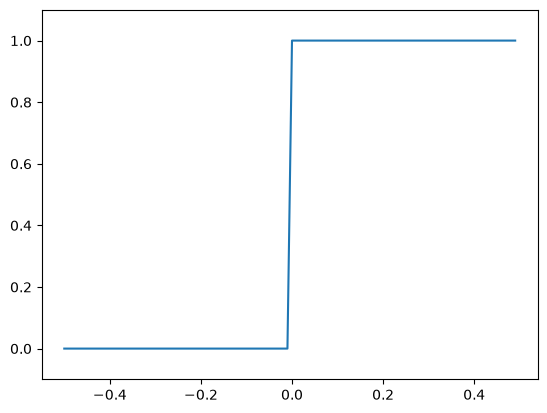

In [108]:
import matplotlib.pylab as plt
import numpy as np

def step_function(x):
    return np.array(x > 0, dtype = int)
## 왜 return 을 np.array 로 하는 건가?

x = np.arange(-0.5, 0.5, 0.01)
y = step_function(x)

plt.plot(x, y)
plt.ylim(-0.1, 1.1)

plt.show()


## 2-4. 시그모이드 함수
$$h(x) = \frac{1}{1 + \exp(-x)}$$
`np.exp`를 쓰면 배열이 들어와도 원소마다 계산된다(브로드캐스트).

In [109]:
def sigmoid(x):
    return 1/(1 + np.exp(-x))


In [110]:
# 확인
check(sigmoid(0), 0.5, 'sigmoid(0)')
check(sigmoid(np.array([-1.0, 1.0, 2.0])), np.array([0.26894142, 0.73105858, 0.88079708]), 'sigmoid(배열)')
print('통과!')

sigmoid(0) = np.float64(0.5)   (정답 0.5) ✅
sigmoid(배열) = array([0.26894142, 0.73105858, 0.88079708])   (정답 array([0.26894142, 0.73105858, 0.88079708])) ✅
통과!


## 2-5. 그래프로 비교하기
`x = np.arange(-5.0, 5.0, 0.1)`로 x를 만들고, 계단 함수와 시그모이드를 **한 그래프에** 그리자.
- 계단 함수는 점선(`linestyle='--'`)으로
- y축 범위는 `plt.ylim(-0.1, 1.1)`

그려 보고 생각해 보기: 둘의 **공통점**과 **차이점**은?

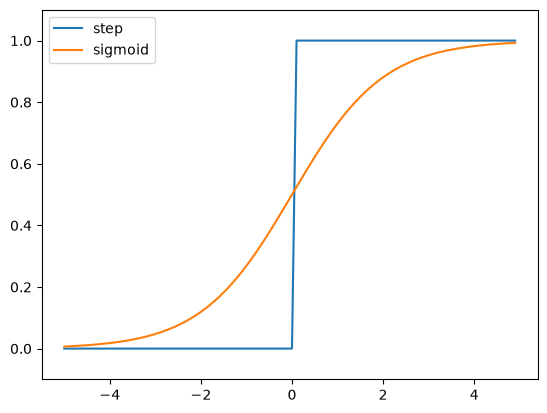

In [111]:
# 여기에 작성
x = np.arange(-5.0, 5.0, 0.1)

y_step = step_function(x)

y_sigmoid = sigmoid(x)

plt.plot(x, y_step, label = "step")
plt.plot(x, y_sigmoid, label = "sigmoid")
plt.ylim(-0.1, 1.1)
plt.legend()

plt.show()


## 2-6. 왜 비선형이어야 할까?
활성화 함수가 선형 $h(x) = cx$라면, 3층을 쌓아도 $y = h(h(h(x)))$이다.
$c = 2$일 때
- `y3`: `h(h(h(1)))` 결과
- `c_one`: 이걸 **한 층** $y = c' x$로 쓰면 $c'$는?

→ 층을 쌓아도 결국 한 층과 똑같아진다는 것이 핵심.

In [112]:
c = 2
def h(x):
    return c * x

y3 =  8     # 여기에 작성
c_one = 8   # 여기에 작성


In [113]:
# 확인
check(y3, 8, 'y3')
check(c_one, 8, 'c_one')
print('통과!')

y3 = 8   (정답 8) ✅
c_one = 8   (정답 8) ✅
통과!


## 2-7. ReLU 함수
$$h(x) = \begin{cases} x & (x > 0) \\ 0 & (x \le 0) \end{cases}$$
`np.maximum(0, x)`를 쓰자. (`np.max`가 아님!)

In [114]:
def relu(x):
    return np.maximum(0, x)

In [115]:
# 확인
check(relu(np.array([-2.0, 0.0, 3.0])), np.array([0.0, 0.0, 3.0]), 'relu')
print('통과!')

relu = array([0., 0., 3.])   (정답 array([0., 0., 3.])) ✅
통과!


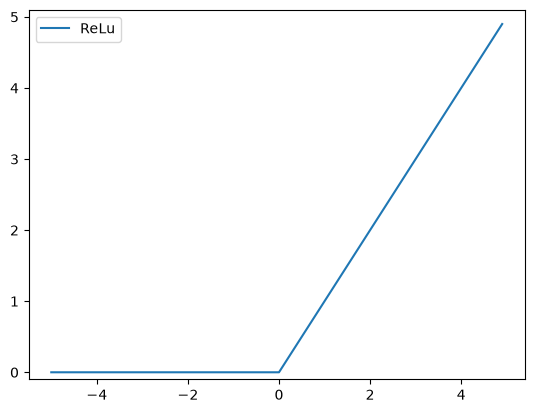

In [116]:
x = np.arange(-5.0, 5.0, 0.1)
y = relu(x)

plt.plot(x, y, label="ReLu")
plt.ylim(-0.1, 5.1)
plt.legend()
plt.show()

# Part 3. 다차원 배열의 계산 (3.3)
## 3-1. 실행 전에 예측하기 — 차원과 모양
```python
B = np.array([[1, 2], [3, 4], [5, 6]])
```
- `ndim_B`: `np.ndim(B)`
- `shape_B`: `B.shape` (튜플로)

In [117]:
ndim_B = 2    # 여기에 작성
shape_B = (3, 2)   # 여기에 작성


In [118]:
# 확인
B = np.array([[1, 2], [3, 4], [5, 6]])
check(ndim_B, np.ndim(B), 'ndim_B')
check(shape_B, B.shape, 'shape_B')
print('통과!')

ndim_B = 2   (정답 2) ✅
shape_B = (3, 2)   (정답 (3, 2)) ✅
통과!


In [119]:
C = np.array([1, 2])
print(C.ndim)
print(C.shape)

1
(2,)


## 3-2. 행렬의 곱 — 손으로 먼저
$$A = \begin{pmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{pmatrix}, \quad B = \begin{pmatrix} 1 & 2 \\ 3 & 4 \\ 5 & 6 \end{pmatrix}$$
1. `AB_hand`: **종이에 계산한** $AB$를 중첩 리스트로 적기 (A의 행 · B의 열)
2. `AB`: `np.dot`으로 계산

In [120]:
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2], [3, 4], [5, 6]])

AB_hand = ([22, 28], [49, 64])   # 여기에 작성 (예: [[?, ?], [?, ?]])
AB = np.dot(A, B)      # 여기에 작성


In [121]:
# 확인
check(AB_hand, [[22, 28], [49, 64]], 'AB_hand')
check(AB, np.array([[22, 28], [49, 64]]), 'AB')
print('통과!')

AB_hand = ([22, 28], [49, 64])   (정답 [[22, 28], [49, 64]]) ✅
AB = array([[22, 28],
       [49, 64]])   (정답 array([[22, 28],
       [49, 64]])) ✅
통과!


## 3-3. 에러 찾기 — 모양이 맞아야 곱할 수 있다
`A`는 `(2, 3)`, `C`는 `(2, 2)`다.

| 기호 | 코드 |
|:-:|:-|
| `'가'` | `np.dot(A, C)` |
| `'나'` | `np.dot(C, A)` |

- `error_case`: **에러가 나는 쪽** (`'가'` 또는 `'나'`)
- `ok_shape`: 에러가 안 나는 쪽의 결과 모양 (튜플)

> 규칙: (행, **열**) · (**행**, 열) — 안쪽 두 숫자가 같아야 한다.

In [122]:
error_case = '가'   # 여기에 작성
ok_shape = (2, 3)     # 여기에 작성


In [123]:
# 확인
C = np.array([[1, 2], [3, 4]])
check(error_case, '가', 'error_case')
check(ok_shape, np.dot(C, A).shape, 'ok_shape')
print('통과!')

error_case = '가'   (정답 '가') ✅
ok_shape = (2, 3)   (정답 (2, 3)) ✅
통과!


## 3-4. 신경망에서의 행렬 곱
입력 2개 → 출력 3개인 신경망(편향·활성화 함수 없음).
$$X = (1,\ 2), \quad W = \begin{pmatrix} 1 & 3 & 5 \\ 2 & 4 & 6 \end{pmatrix}$$
- `Y`: $XW$ (`np.dot` 한 번으로!)
- 생각해 보기: `X.shape`, `W.shape`, `Y.shape`는 각각?

In [124]:
X = np.array([1, 2])
W = np.array([[1, 3, 5], [2, 4, 6]])

Y = np.dot(X, W)


In [125]:
# 확인
check(Y, np.array([5, 11, 17]), 'Y')
print('통과!')

Y = array([ 5, 11, 17])   (정답 array([ 5, 11, 17])) ✅
통과!


# Part 4. 3층 신경망 구현하기 (3.4)
## 4-1. 1층 신호 전달
$$A^{(1)} = XW^{(1)} + B^{(1)}, \qquad Z^{(1)} = h(A^{(1)})$$
- `A1`: 가중합 (편향 더하기까지)
- `Z1`: `A1`에 시그모이드 적용

In [126]:
X = np.array([1.0, 0.5])
W1 = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
B1 = np.array([0.1, 0.2, 0.3])

A1 = np.dot(X, W1) + B1
Z1 = sigmoid(A1)



print(A1)
print(Z1)

[0.3 0.7 1.1]
[0.57444252 0.66818777 0.75026011]


In [127]:
# 확인
check(A1, np.array([0.3, 0.7, 1.1]), 'A1')
check(Z1, np.array([0.57444252, 0.66818777, 0.75026011]), 'Z1')
print('통과!')

A1 = array([0.3, 0.7, 1.1])   (정답 array([0.3, 0.7, 1.1])) ✅
Z1 = array([0.57444252, 0.66818777, 0.75026011])   (정답 array([0.57444252, 0.66818777, 0.75026011])) ✅
통과!


## 4-2. 2층 신호 전달 (은닉층 1 → 은닉층 2)
4-1에서 구한 `Z1`이 이제 2층의 **입력**이 된다.
$$A^{(2)} = Z^{(1)}W^{(2)} + B^{(2)}, \qquad Z^{(2)} = h(A^{(2)})$$
- `shape_A2`: `A2`의 모양 (튜플) — **코드 전에 먼저 예측!** `Z1`은 `(3,)`, `W2`는 `(3, 2)`
- `A2`: 가중합
- `Z2`: 시그모이드 적용

In [128]:
import numpy as np

W2 = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
B2 = np.array([0.1, 0.2])

shape_A2 = (2,)   # 여기에 작성 (예측 먼저)
A2 = np.dot(Z1, W2) + B2       # 여기에 작성
Z2 = sigmoid(A2)        # 여기에 작성


In [129]:
# 확인
check(shape_A2, (2,), 'shape_A2')
check(A2, np.array([0.51615984, 1.21402696]), 'A2')
check(Z2, np.array([0.62624937, 0.7710107]), 'Z2')
print('통과!')

shape_A2 = (2,)   (정답 (2,)) ✅
A2 = array([0.51615984, 1.21402696])   (정답 array([0.51615984, 1.21402696])) ✅
Z2 = array([0.62624937, 0.7710107 ])   (정답 array([0.62624937, 0.7710107 ])) ✅
통과!


## 4-3. 출력층 신호 전달 (은닉층 2 → 출력층)
출력층은 시그모이드 대신 **항등 함수** $\sigma()$를 쓴다. 받은 값을 그대로 돌려주는 함수다.
$$A^{(3)} = Z^{(2)}W^{(3)} + B^{(3)}, \qquad Y = \sigma(A^{(3)})$$
- `identity_function(x)`: 받은 `x`를 그대로 돌려주기
- `A3`, `Y`

> 생각해 보기: 아무것도 안 하는 함수를 왜 굳이 만들까? (은닉층과 **모양을 맞추려고** — 층마다 "가중합 → 활성화 함수" 흐름이 똑같아진다)

In [130]:
W3 = np.array([[0.1, 0.3], [0.2, 0.4]])
B3 = np.array([0.1, 0.2])

def identity_function(x):
    return x

A3 = np.dot(Z2, W3) + B3   # 여기에 작성
Y = identity_function(A3)   # 여기에 작성


In [131]:
# 확인
check(Y, np.array([0.31682708, 0.69627909]), 'Y')
print('통과!')

Y = array([0.31682708, 0.69627909])   (정답 array([0.31682708, 0.69627909])) ✅
통과!


## 4-4. 구현 정리 — 4-1~4-3을 `init_network()`와 `forward()`로 묶기
아래 `init_network()`는 완성되어 있다. 이걸 쓰는 `forward(network, x)`를 만들자.
- 1층, 2층: 가중합 → **시그모이드**
- 3층(출력층): 가중합 → **항등 함수** `identity_function` (받은 값을 그대로 돌려줌)

딕셔너리에서 꺼내기: `W1, W2, W3 = network['W1'], network['W2'], network['W3']`

In [132]:
def init_network():
    network = {}
    network['W1'] = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
    network['b1'] = np.array([0.1, 0.2, 0.3])
    network['W2'] = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
    network['b2'] = np.array([0.1, 0.2])
    network['W3'] = np.array([[0.1, 0.3], [0.2, 0.4]])
    network['b3'] = np.array([0.1, 0.2])
    return network


In [133]:
def identity_function(x):
    return x

def forward(network, x):
    W1 , W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']
    a1 = np.dot(x, W1) + b1
    Z1 = sigmoid(a1)
    a2 = np.dot(Z1, W2) + b2
    Z2 = sigmoid(a2)

    a3 = np.dot(Z2, W3) + b3

    y = identity_function(a3)

    return y


In [134]:
# 확인
network = init_network()
y = forward(network, np.array([1.0, 0.5]))
check(y, np.array([0.31682708, 0.69627909]), 'forward 결과')
print('통과!')

forward 결과 = array([0.31682708, 0.69627909])   (정답 array([0.31682708, 0.69627909])) ✅
통과!


# Part 5. 출력층 설계하기 (3.5)
## 5-1. 소프트맥스 함수 (기본형)
$$y_k = \frac{\exp(a_k)}{\sum_{i=1}^{n} \exp(a_i)}$$
`softmax_naive(a)`를 만들자. 분모는 `np.sum(np.exp(a))`.

In [135]:
def softmax_naive(a):
    exp_a = np.exp(a)
    exp_sum = np.sum(np.exp(a))

    y = exp_a/exp_sum
    return y


In [136]:
# 확인
y = softmax_naive(np.array([0.3, 2.9, 4.0]))
check(y, np.array([0.01821127, 0.24519181, 0.73659691]), 'softmax_naive')
check(np.sum(y), 1.0, '합')
print('통과!')

softmax_naive = array([0.01821127, 0.24519181, 0.73659691])   (정답 array([0.01821127, 0.24519181, 0.73659691])) ✅
합 = np.float64(1.0)   (정답 1.0) ✅
통과!


## 5-2. 실행 전에 예측하기 — 오버플로
`softmax_naive(np.array([1010, 1000, 990]))`를 실행하면 어떻게 될까?
- `predict_overflow`: `'정상'` 또는 `'nan'` 중 하나

> 힌트: `np.exp(1010)`은 컴퓨터가 표현할 수 있는 수보다 크다 → `inf`. 그럼 `inf / inf`는?

In [137]:
predict_overflow = 'nan'  # 여기에 작성


In [138]:
# 확인 (경고 메시지가 떠도 정상이다)
print(softmax_naive(np.array([1010, 1000, 990])))
check(predict_overflow, 'nan', 'predict_overflow')
print('통과!')

[nan nan nan]
predict_overflow = 'nan'   (정답 'nan') ✅
통과!


C:\Users\sdj03\AppData\Local\Temp\ipykernel_29568\3901177549.py:2: RuntimeWarning: overflow encountered in exp
  exp_a = np.exp(a)
C:\Users\sdj03\AppData\Local\Temp\ipykernel_29568\3901177549.py:3: RuntimeWarning: overflow encountered in exp
  exp_sum = np.sum(np.exp(a))
C:\Users\sdj03\AppData\Local\Temp\ipykernel_29568\3901177549.py:5: RuntimeWarning: invalid value encountered in divide
  y = exp_a/exp_sum


## 5-3. 오버플로를 막는 소프트맥스
입력 전체에서 **최댓값 `c`를 빼고** 계산해도 결과는 같다. (분자·분모에 같은 수 $\exp(-c)$를 곱한 셈)
`softmax(a)`를 만들자.

In [139]:
def softmax(a):
    max_ele = np.max(a)
    exp_norm = np.exp(a - max_ele)
    norm_sum = np.sum(exp_norm)

    y = exp_norm / norm_sum

    return y



In [140]:
# 확인
check(softmax(np.array([1010, 1000, 990])), np.array([9.99954600e-01, 4.53978686e-05, 2.06106005e-09]), 'softmax(큰 값)')
check(softmax(np.array([0.3, 2.9, 4.0])), np.array([0.01821127, 0.24519181, 0.73659691]), 'softmax(작은 값)')
print('통과!')

softmax(큰 값) = array([9.99954600e-01, 4.53978686e-05, 2.06106005e-09])   (정답 array([9.99954600e-01, 4.53978686e-05, 2.06106005e-09])) ✅
softmax(작은 값) = array([0.01821127, 0.24519181, 0.73659691])   (정답 array([0.01821127, 0.24519181, 0.73659691])) ✅
통과!


## 5-4. 소프트맥스의 특징
`a = np.array([0.3, 2.9, 4.0])`일 때
- `idx_a`: `np.argmax(a)` (가장 큰 값의 **인덱스**)
- `idx_y`: `np.argmax(softmax(a))`
- `same`: 둘이 같은가? (`True`/`False`)

→ 그래서 **추론**할 때는 출력층 소프트맥스를 생략하기도 한다.

In [141]:
a = np.array([0.3, 2.9, 4.0])

idx_a = np.argmax(a)  # 여기에 작성
idx_y = np.argmax(softmax(a))  # 여기에 작성
same = True   # 여기에 작성


In [142]:
# 확인
check(idx_a, 2, 'idx_a')
check(idx_y, 2, 'idx_y')
check(same, True, 'same')
print('통과!')

idx_a = np.int64(2)   (정답 2) ✅
idx_y = np.int64(2)   (정답 2) ✅
same = True   (정답 True) ✅
통과!


## 5-5. 출력층의 뉴런 수
손글씨 숫자(0~9) 이미지를 보고 어떤 숫자인지 맞히는 **분류** 문제다.
- `n_output`: 출력층 뉴런 수
- `output_fn`: 출력층에 주로 쓰는 함수 (`'identity'` 또는 `'softmax'`)

In [143]:
n_output = 10    # 여기에 작성
output_fn = 'softmax'   # 여기에 작성


In [144]:
# 확인
check(n_output, 10, 'n_output')
check(output_fn, 'softmax', 'output_fn')
print('통과!')

n_output = 10   (정답 10) ✅
output_fn = 'softmax'   (정답 'softmax') ✅
통과!


# Part 6. 손글씨 숫자 인식 (3.6) — 책 코드 따라 하기
진짜 MNIST 데이터로 책 3.6의 코드를 **그대로** 따라 쳐 본다.
(작은 데이터로 다시 연습하는 문제는 뒤의 Part 7에 있다.)

**준비물** (이미 복사해 둠)
- `C:\Deeplerning\dataset\mnist.py` + `.gz` 파일 4개
- `C:\Deeplerning\ch03_neural_network\sample_weight.pkl`

> 앞에서 만든 `sigmoid`, `softmax`를 쓰니까 **0번 준비 셀부터 순서대로** 실행해 두자.

## 6-1. MNIST 불러오기 (3.6.1)
책 코드를 따라 `load_mnist(flatten=True, normalize=False)`로 데이터 4개를 받자.

경로는 책과 **똑같이** `sys.path.append(os.pardir)`면 된다.
노트북은 `ch03_neural_network`에서 실행되고, 한 칸 위(`C:\Deeplerning`)에 `dataset`이 있기 때문이다.

> 처음 실행하면 `Converting ...` 메시지가 뜨고 `dataset` 폴더에 `mnist.pkl`이 생긴다. 몇 초 걸린다.

In [148]:
import sys, os
sys.path.append(os.pardir)   # 한 칸 위 폴더(C:\Deeplerning)도 찾아보게 하기
from dataset.mnist import load_mnist


(x_train, t_trian), (x_test, t_test) = load_mnist(flatten=True, normalize=False)

**실행 전에 예측하기** — 네 배열의 `shape`는? (튜플로)
> 힌트: 훈련 6만 장, 시험 1만 장. 이미지 1장 = 28×28 = 784개 숫자. 정답(`t`)은 장마다 숫자 **하나**.

In [152]:
pred_x_train = (60000, 784)   # 여기에 작성
pred_t_train = (60000, )   # 여기에 작성
pred_x_test = (10000, 784)    # 여기에 작성
pred_t_test = (10000, )    # 여기에 작성

## test 변수들의 차원 예측을 틀림 -> 결국 정답으로 하나가 나오기 때문에 해당 1차원이 됨. 


In [153]:
# 확인 (shape는 괄호 없이!)
print(x_train.shape, t_train.shape, x_test.shape, t_test.shape)
check(pred_x_train, x_train.shape, 'x_train.shape')
check(pred_t_train, t_train.shape, 't_train.shape')
check(pred_x_test, x_test.shape, 'x_test.shape')
check(pred_t_test, t_test.shape, 't_test.shape')
print('통과!')

(60000, 784) (60000,) (10000, 784) (10000,)
x_train.shape = (60000, 784)   (정답 (60000, 784)) ✅
t_train.shape = (60000,)   (정답 (60000,)) ✅
x_test.shape = (10000, 784)   (정답 (10000, 784)) ✅
t_test.shape = (10000,)   (정답 (10000,)) ✅
통과!


## 6-2. 이미지 한 장 보기 (3.6.1)
첫 번째 훈련 이미지 `x_train[0]`과 정답 `t_train[0]`을 꺼내 보자.
- `img`: 첫 번째 이미지 → `reshape(28, 28)`로 원래 모양으로 되돌리기
- `label`: 첫 번째 정답

> 📝 **책과 다른 점:** 책의 `img_show()`는 PIL로 **새 창**을 띄운다. 노트북에서는 `plt.imshow(img, cmap='gray')`로 셀 아래에 바로 보이게 하자.

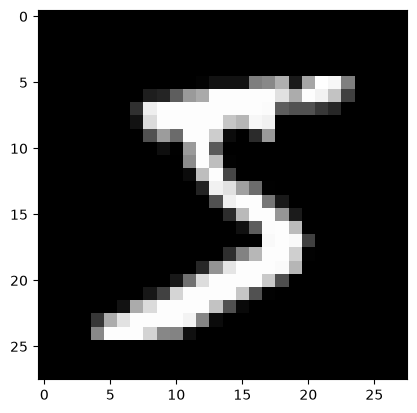

5


In [156]:
# 여기에 작성
import matplotlib.pyplot as plt

img_raw = x_train[0]

img = img_raw.reshape(28, 28)

label = t_trian[0]

plt.imshow(img, cmap='gray')
plt.show()

print(label)

In [157]:
# 확인
check(int(label), 5, 'label')
check(img.shape, (28, 28), 'img.shape')
print('통과!')

label = 5   (정답 5) ✅
img.shape = (28, 28)   (정답 (28, 28)) ✅
통과!


## 6-3. 신경망 추론 준비 (3.6.2)
책의 함수 3개를 따라 만들자.
- `get_data()`: **시험 데이터**만 돌려줌. 이번엔 `normalize=True` (픽셀 0~255 → 0.0~1.0, **정규화**)
- `init_network()`: `sample_weight.pkl`을 `pickle`로 읽어서 가중치 딕셔너리를 돌려줌
- `predict(network, x)`: 4-4의 `forward()`와 같은 흐름. 단 출력층은 **`softmax`**

> 📝 경로: `sample_weight.pkl`이 노트북과 **같은 폴더**에 있어서 책처럼 파일 이름만 쓰면 된다.
> ⚠️ 4-4의 `init_network()`와 이름이 같아서 덮어쓰게 된다. 4-4를 다시 확인하려면 4-4 셀을 다시 실행.

In [161]:
import pickle

def get_data():
    (x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, flatten=True, one_hot_label=False)
    return (x_train, t_train)

def init_network():
    with open('sample_weight.pkl', 'rb') as f:
        network = pickle.load(f)

        return network

def predict(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3'] 
    b1, b2, b3 = network['b1'], network['b2'], network['b3']

    a1 = np.dot(x, W1) +b1
    Z1 = sigmoid(a1)

    a2 = np.dot(Z1, W2) + b2
    Z2 = sigmoid(a2)

    a3 = np.dot(Z2, W3) + b3

    y = softmax(a3)

    return y

In [162]:
# 확인
x, t = get_data()
network = init_network()
y0 = predict(network, x[0])
print('x[0]의 출력:', np.round(y0, 3))
check(network['W1'].shape, (784, 50), 'W1.shape')
check(y0.shape, (10,), '출력 shape')
check(float(np.sum(y0)), 1.0, '출력의 합')
print('통과!')

x[0]의 출력: [0.011 0.    0.    0.216 0.    0.768 0.    0.003 0.002 0.001]
W1.shape = (784, 50)   (정답 (784, 50)) ✅
출력 shape = (10,)   (정답 (10,)) ✅
출력의 합 = 0.9999999403953552   (정답 1.0) ✅
통과!


## 6-4. 정확도 계산 (3.6.2)
시험 이미지 1만 장을 **한 장씩** `predict` → `np.argmax`로 가장 확률 높은 숫자를 고르고, 정답 `t[i]`와 같으면 `accuracy_cnt`를 1 늘리자.

책에 나온 정확도는 **0.9352**. 같은 값이 나오는지 보자.

In [166]:
x, t = get_data()
network = init_network()

accuracy_cnt = 0
# 여기에 작성 (for i in range(len(x)): ...)
y = predict(network, x)

for i in range(len(x)):
    if np.argmax(y[i]) == t[i]:
        accuracy_cnt += 1

    else:
        pass


    

print('Accuracy:' + str(float(accuracy_cnt) / len(x)))


Accuracy:0.9357666666666666


In [169]:
accuracy_cnt = 0

for i in range(len(x)):
    y = predict(network, x[i])   # 한 장씩
    p = np.argmax(y)
    if p == t[i]:
        accuracy_cnt += 1

print('Accuracy:' + str(float(accuracy_cnt) / len(x)))


Accuracy:0.9357666666666666


In [171]:
# 확인
check(accuracy_cnt / len(x), 0.9352, 'Accuracy')
print('통과!')

Accuracy = 0.9357666666666666   (정답 0.9352) ❌


AssertionError: Accuracy 이(가) 틀렸어요

## 6-5. 배치 처리 — 모양 확인 (3.6.3)
**실행 전에 예측하기** — 책처럼 모양을 따라가 보자. (튜플로)
- `pred_x0`: `x[0].shape` (이미지 1장)
- `pred_W1`, `pred_W2`, `pred_W3`: 가중치 모양
- `pred_batch_out`: 이미지 **100장**(`x[0:100]`)을 한꺼번에 `predict`했을 때 출력 모양

> 힌트: 행렬 곱은 안쪽 숫자가 사라지고 바깥 숫자가 남는다. `(100, 784)·(784, 50) → ?`

In [ ]:
pred_x0 = None          # 여기에 작성
pred_W1 = None          # 여기에 작성
pred_W2 = None          # 여기에 작성
pred_W3 = None          # 여기에 작성
pred_batch_out = None   # 여기에 작성


In [ ]:
# 확인
W1, W2, W3 = network['W1'], network['W2'], network['W3']
print(x.shape, x[0].shape, W1.shape, W2.shape, W3.shape)
check(pred_x0, x[0].shape, 'x[0].shape')
check(pred_W1, W1.shape, 'W1.shape')
check(pred_W2, W2.shape, 'W2.shape')
check(pred_W3, W3.shape, 'W3.shape')
check(pred_batch_out, predict(network, x[0:100]).shape, '배치 출력 shape')
print('통과!')

## 6-6. 배치로 정확도 계산 (3.6.3)
6-4를 **100장씩** 묶어서 하자. 책 코드 흐름:
1. `for i in range(0, len(x), batch_size):`로 100씩 건너뛰며
2. `x_batch = x[i:i+batch_size]`로 100장 잘라서 `predict`
3. `np.argmax(y_batch, axis=1)`로 **행마다** 답 고르기
4. `np.sum(p == t[i:i+batch_size])`로 맞힌 개수 더하기

결과가 6-4와 **똑같이** 0.9352가 나와야 한다. (훨씬 빨라진 것도 느껴 보자)

In [ ]:
x, t = get_data()
network = init_network()

batch_size = 100
accuracy_cnt = 0
# 여기에 작성

print('Accuracy:' + str(float(accuracy_cnt) / len(x)))


In [ ]:
# 확인
check(accuracy_cnt / len(x), 0.9352, 'Accuracy (배치)')
print('통과!')

# Part 7. 반복 연습 — 3.6 핵심을 작은 데이터로
Part 6에서 책 코드로 해 본 것을 **작은 가짜 데이터**로 다시 연습한다.
숫자가 작아서 손으로 따라가며 확인하기 좋다.

## 7-1. 정확도 계산 (한 장씩)
신경망 출력 `y_list`(이미지 4장)와 정답 레이블 `t`가 있다.
for문으로 한 장씩 `np.argmax`를 구해 맞힌 개수 `accuracy_cnt`를 세자.

In [ ]:
## 깃허브 링크 받아와서 수 분류 작업 진행하기
import sys, os
sys.path.append(os.pardir)
from dataset.mnist import load_mnist


(x_train, t_train), (x_test, t_test) = load_mnist(flatten=True, normalize=False)


print(x_train.shape)

print(x_train.shape)

print(t_train.shape)

print(x_test.shape)

print(t_test.shape)


(60000, 784)
(60000, 784)
(60000,)
(10000, 784)
(10000,)


In [ ]:
y_list = np.array([[0.1, 0.8, 0.1],
                   [0.3, 0.1, 0.6],
                   [0.2, 0.5, 0.3],
                   [0.8, 0.1, 0.1]])
t = np.array([1, 2, 1, 0])

accuracy_cnt = 0
# 여기에 작성 (for i in range(len(y_list)): ...)

print('Accuracy:', accuracy_cnt / len(t))


In [ ]:
# 확인
check(accuracy_cnt, 4, 'accuracy_cnt')
print('통과!')

## 7-2. 배치 처리 — 모양 따라가기
이미지 100장을 한꺼번에 넣는다. (MNIST 이미지 1장 = 784개 숫자)

| | 모양 |
|:-:|:-:|
| `X` | (100, 784) |
| `W1` | (784, 50) |
| `W2` | (50, 100) |
| `W3` | (100, 10) |

- `shape_y`: 최종 출력 `Y`의 모양 (튜플)
- 생각해 보기: 출력의 첫 번째 숫자는 무엇을, 두 번째 숫자는 무엇을 뜻할까?

In [ ]:
shape_y = None   # 여기에 작성


In [ ]:
# 확인 (진짜로 곱해 보기)
Xb = np.random.rand(100, 784)
Y = np.dot(np.dot(np.dot(Xb, np.random.rand(784, 50)), np.random.rand(50, 100)), np.random.rand(100, 10))
check(shape_y, Y.shape, 'shape_y')
print('통과!')

## 7-3. 실행 전에 예측하기 — 배치로 자르기
```python
x = np.arange(10)      # 0~9, 10장이라고 치자
batch_size = 3
for i in range(0, len(x), batch_size):
    x_batch = x[i:i+batch_size]
```
- `starts`: `i`가 차례로 갖는 값들 (리스트)
- `last_batch`: 마지막 `x_batch` (리스트)

> 슬라이싱 `x[i:i+3]`은 **끝 인덱스를 포함하지 않는다**는 것, 범위를 넘어가도 에러 없이 있는 만큼만 준다는 것을 떠올리자.

In [ ]:
starts = None       # 여기에 작성
last_batch = None   # 여기에 작성


In [ ]:
# 확인 (이제 실행해서 맞춰 보기)
x = np.arange(10)
batch_size = 3
real_starts = []
for i in range(0, len(x), batch_size):
    x_batch = x[i:i+batch_size]
    real_starts.append(i)
    print(i, x_batch)
check(starts, real_starts, 'starts')
check(last_batch, list(x_batch), 'last_batch')
print('통과!')

## 7-4. 배치로 정확도 계산 (`axis=1`)
7-1을 for문 없이! `y_list` 전체에 `np.argmax(..., axis=1)`을 쓰면 **행마다** 최댓값 인덱스를 준다.
- `p`: 행마다의 argmax
- `acc`: `np.sum(p == t)`로 맞힌 개수를 세서 정확도(0~1) 계산

> `axis=0`이면 **열마다**가 된다. 헷갈리면 둘 다 출력해 보자.

In [ ]:
p = None     # 여기에 작성
acc = None   # 여기에 작성


In [ ]:
# 확인
check(p, np.array([1, 2, 1, 0]), 'p')
check(acc, 1.0, 'acc')
print('통과!')

# 끝!
다 풀었으면 `ch03_solutions.ipynb`와 비교해 보자.
